## Setup and Load the Data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True


def load_folder(folder):
    files = sorted(Path(folder).glob("*.parquet"))
    return pd.concat((pd.read_parquet(f) for f in files), ignore_index=True)


neso = load_folder("../data/raw/neso_intensity")
weather = load_folder("../data/raw/weather")

# Time features in both UTC and UK local time
neso["local"] = neso["period_start"].dt.tz_convert("Europe/London")
neso["hour_utc"] = neso["period_start"].dt.hour + neso["period_start"].dt.minute / 60
neso["hour_local"] = neso["local"].dt.hour + neso["local"].dt.minute / 60
neso["hour_int"] = neso["local"].dt.hour
neso["dow"] = neso["local"].dt.dayofweek
neso["month"] = neso["local"].dt.month
neso["is_weekend"] = neso["dow"] >= 5
neso["is_bst"] = (
    neso["local"].dt.tz_localize(None) - neso["period_start"].dt.tz_localize(None)
) == pd.Timedelta("1h")

print(neso.shape, weather.shape)
neso.head()

(66334, 13) (132384, 6)


,period_start,period_end,forecast,actual,intensity_index,local,hour_utc,hour_local,hour_int,dow,month,is_weekend,is_bst
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,73.0,72.0,low,2023-01-01 00:00:00+00:00,0.0,0.0,0,6,1,True,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,63.0,80.0,low,2023-01-01 00:30:00+00:00,0.5,0.5,0,6,1,True,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,71.0,72.0,low,2023-01-01 01:00:00+00:00,1.0,1.0,1,6,1,True,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,76.0,65.0,low,2023-01-01 01:30:00+00:00,1.5,1.5,1,6,1,True,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,72.0,65.0,low,2023-01-01 02:00:00+00:00,2.0,2.0,2,6,1,True,False


## long-term trend (analysis 1)

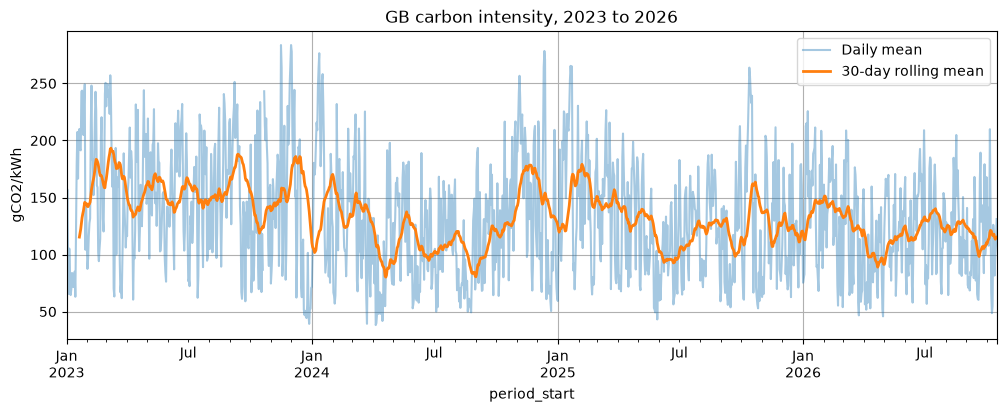

,mean,median,std
period_start,,,
2023,152.1,153.0,62.7
2024,125.1,116.0,59.9
2025,129.2,124.0,57.6
2026,121.9,118.0,53.0


In [2]:
daily = neso.set_index("period_start")["actual"].resample("D").mean()

ax = daily.plot(alpha=0.4, label="Daily mean")
daily.rolling(30, min_periods=20).mean().plot(ax=ax, linewidth=2, label="30-day rolling mean")
ax.set_title("GB carbon intensity, 2023 to 2026")
ax.set_ylabel("gCO2/kWh")
ax.legend()
plt.show()

neso.groupby(neso["period_start"].dt.year)["actual"].agg(["mean", "median", "std"]).round(1)

## daily profile, UTC vs local time (analysis 2 and the time zone check)

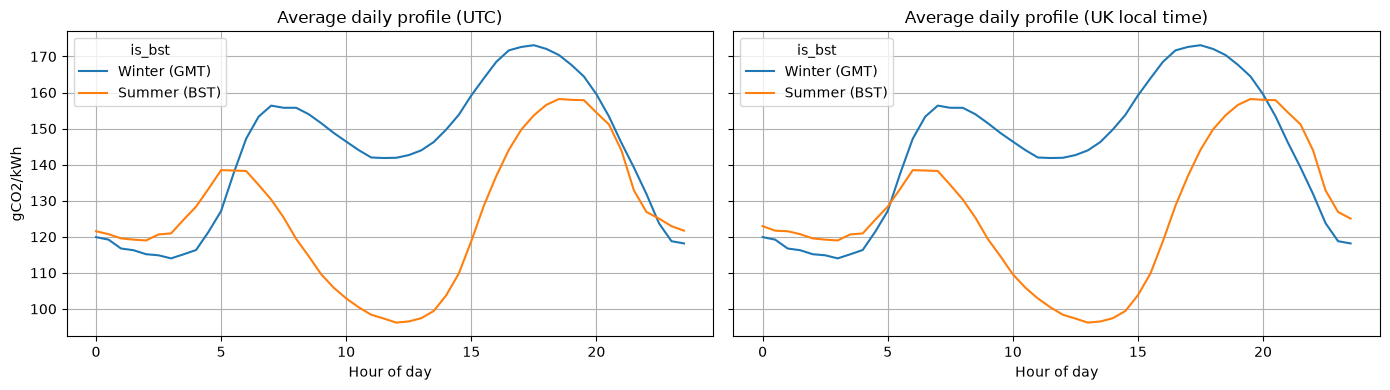

Evening peak by season (hour_utc): {'GMT': 17.5, 'BST': 18.5}
Evening peak by season (hour_local): {'GMT': 17.5, 'BST': 19.5}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, col, title in [(axes[0], "hour_utc", "UTC"), (axes[1], "hour_local", "UK local time")]:
    prof = neso.groupby(["is_bst", col])["actual"].mean().unstack(0)
    prof = prof.rename(columns={False: "Winter (GMT)", True: "Summer (BST)"})
    prof.plot(ax=ax)
    ax.set_title(f"Average daily profile ({title})")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("gCO2/kWh")

plt.tight_layout()
plt.show()

for col in ["hour_utc", "hour_local"]:
    evening = neso[neso[col] >= 14]
    peaks = evening.groupby(["is_bst", col])["actual"].mean().groupby(level=0).idxmax()
    print(f"Evening peak by season ({col}):", {("BST" if k else "GMT"): v[1] for k, v in peaks.items()})
    

## weekday vs weekend (analysis 3)

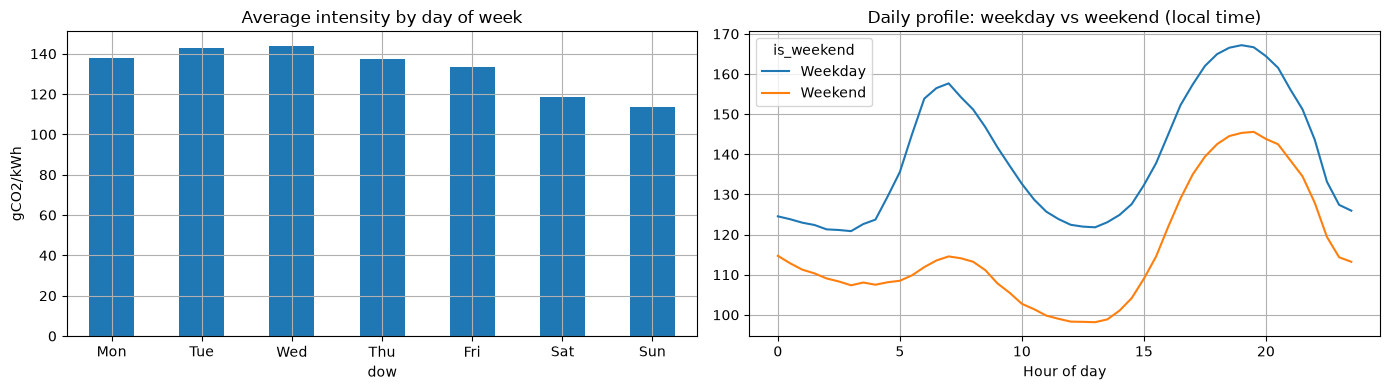

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

neso.groupby("dow")["actual"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[0].set_title("Average intensity by day of week")
axes[0].set_ylabel("gCO2/kWh")

(
    neso.groupby(["is_weekend", "hour_local"])["actual"].mean()
    .unstack(0)
    .rename(columns={False: "Weekday", True: "Weekend"})
    .plot(ax=axes[1])
)
axes[1].set_title("Daily profile: weekday vs weekend (local time)")
axes[1].set_xlabel("Hour of day")

plt.tight_layout()
plt.show()

## seasonality (analysis 4)

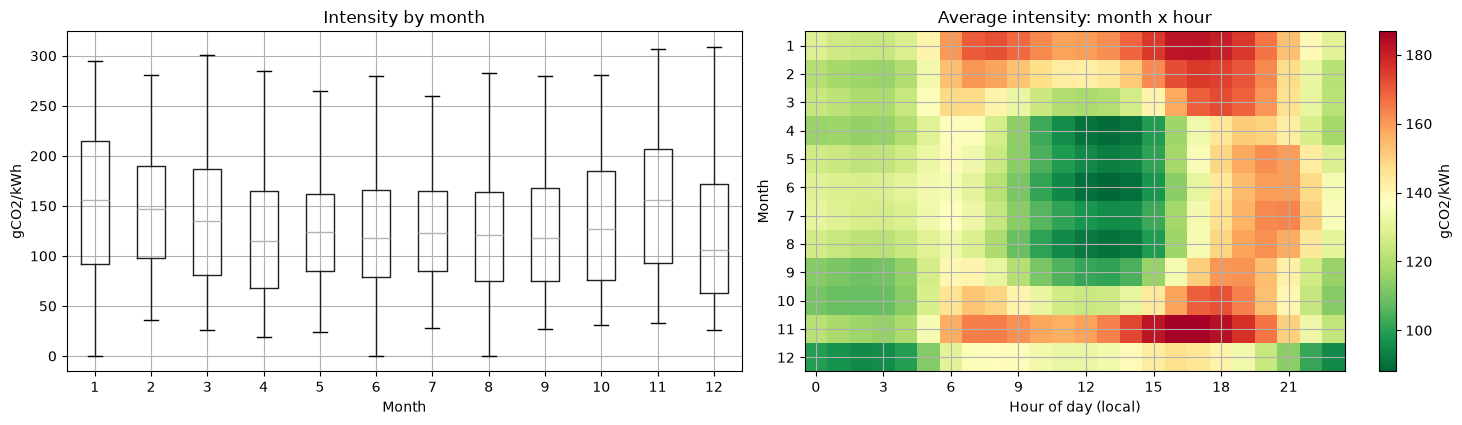

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

neso.boxplot(column="actual", by="month", ax=axes[0], showfliers=False)
axes[0].set_title("Intensity by month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("gCO2/kWh")
fig.suptitle("")

heat = neso.pivot_table(index="month", columns="hour_int", values="actual", aggfunc="mean")
im = axes[1].imshow(heat, aspect="auto", cmap="RdYlGn_r")
axes[1].set_yticks(range(len(heat.index)), labels=heat.index)
axes[1].set_xticks(range(0, 24, 3), labels=range(0, 24, 3))
axes[1].set_xlabel("Hour of day (local)")
axes[1].set_ylabel("Month")
axes[1].set_title("Average intensity: month x hour")
fig.colorbar(im, ax=axes[1], label="gCO2/kWh")

plt.tight_layout()
plt.show()

In [12]:
low = neso[neso["actual"] <= 20].sort_values("actual")
print("Rows with actual <= 20:", len(low))
low[["period_start", "forecast", "actual", "intensity_index"]].head(20)

Rows with actual <= 20: 12


,period_start,forecast,actual,intensity_index
1442,2023-01-31 01:00:00+00:00,89.0,0.0,very low
7555,2023-06-07 09:30:00+00:00,185.0,0.0,very low
7556,2023-06-07 10:00:00+00:00,176.0,0.0,very low
7557,2023-06-07 10:30:00+00:00,170.0,0.0,very low
7558,2023-06-07 11:00:00+00:00,164.0,0.0,very low
62924,2026-08-06 11:00:00+00:00,62.0,0.0,very low
24893,2024-06-04 12:00:00+00:00,45.0,14.0,very low
22494,2024-04-15 12:30:00+00:00,19.0,19.0,very low
22495,2024-04-15 13:00:00+00:00,16.0,19.0,very low
22493,2024-04-15 12:00:00+00:00,20.0,20.0,very low


## weather vs intensity (analysis 5)

In [11]:
variables = ["wind_speed_100m", "shortwave_radiation", "cloud_cover", "temperature_2m"]
wide = weather.pivot_table(index="time", columns="location", values=variables)
wide.columns = [f"{var}__{loc}" for var, loc in wide.columns]

neso["hour_key"] = neso["period_start"].dt.floor("h")
merged = neso.merge(wide, left_on="hour_key", right_index=True, how="inner")
print("Merged rows:", len(merged))

corr = merged[wide.columns].corrwith(merged["actual"], method="spearman").sort_values()
corr.round(2)

Merged rows: 66070


wind_speed_100m__north_sea                 -0.55
wind_speed_100m__london                    -0.45
wind_speed_100m__south_england_solar       -0.43
wind_speed_100m__scotland_wind             -0.29
temperature_2m__south_england_solar        -0.19
temperature_2m__london                     -0.19
temperature_2m__north_sea                  -0.18
temperature_2m__scotland_wind              -0.12
shortwave_radiation__london                -0.09
shortwave_radiation__north_sea             -0.08
shortwave_radiation__south_england_solar   -0.08
shortwave_radiation__scotland_wind         -0.07
cloud_cover__scotland_wind                 -0.04
cloud_cover__south_england_solar            0.02
cloud_cover__london                         0.02
cloud_cover__north_sea                      0.04
dtype: float64

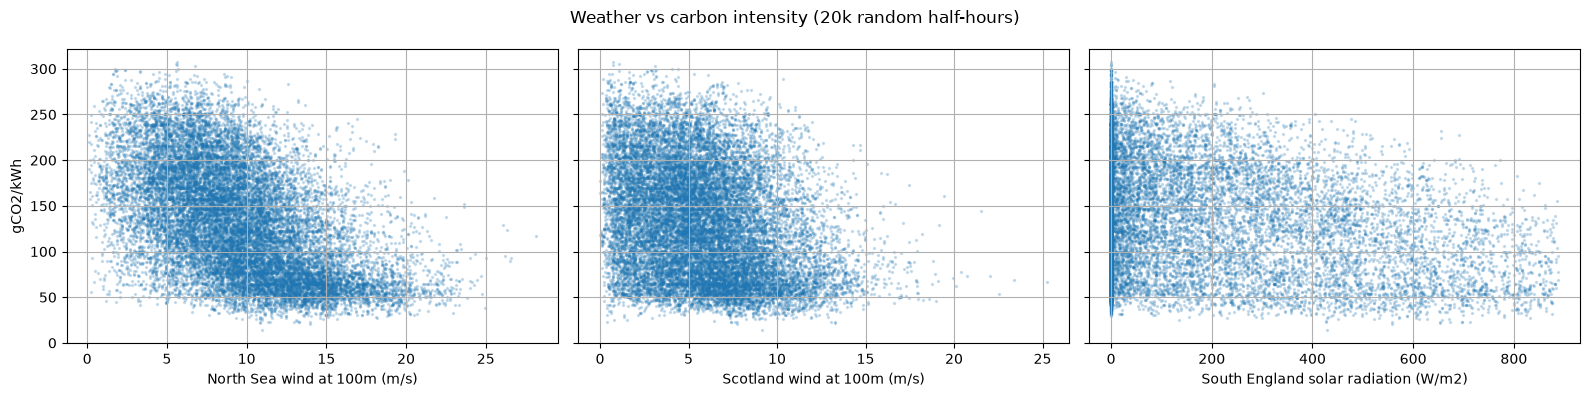

In [7]:
sample = merged.dropna(subset=["actual"]).sample(20000, random_state=42)
pairs = [
    ("wind_speed_100m__north_sea", "North Sea wind at 100m (m/s)"),
    ("wind_speed_100m__scotland_wind", "Scotland wind at 100m (m/s)"),
    ("shortwave_radiation__south_england_solar", "South England solar radiation (W/m2)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (col, label) in zip(axes, pairs):
    ax.scatter(sample[col], sample["actual"], s=2, alpha=0.2)
    ax.set_xlabel(label)
axes[0].set_ylabel("gCO2/kWh")
fig.suptitle("Weather vs carbon intensity (20k random half-hours)")
plt.tight_layout()
plt.show()

## Autocorrelation

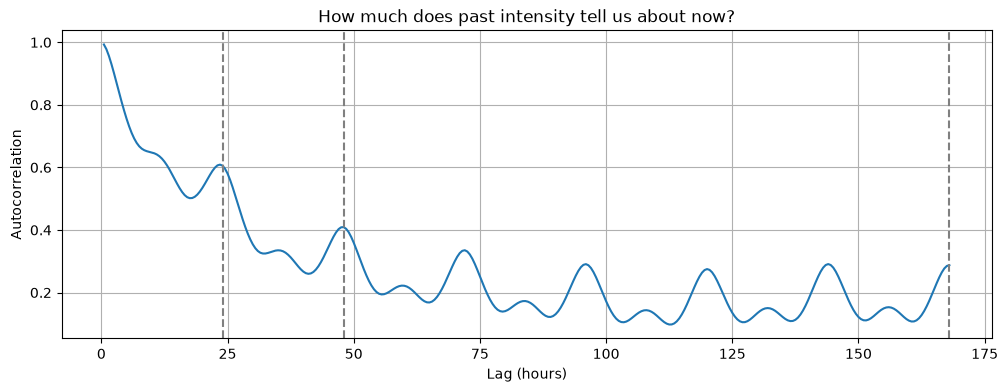

{'0.5h': np.float64(0.993), '1h': np.float64(0.978), '6h': np.float64(0.71), '24h': np.float64(0.606), '48h': np.float64(0.409), '168h': np.float64(0.287)}


In [8]:
series = neso.set_index("period_start")["actual"].asfreq("30min")  # outages become NaN, not shifted
lags = range(1, 337)  # up to 7 days
acf = pd.Series([series.autocorr(lag) for lag in lags], index=[lag / 2 for lag in lags])

ax = acf.plot()
for h in [24, 48, 168]:
    ax.axvline(h, linestyle="--", color="grey")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.set_title("How much does past intensity tell us about now?")
plt.show()

print({f"{h}h": round(acf[h], 3) for h in [0.5, 1, 6, 24, 48, 168]})

## NESO forecast error profile

NESO MAE: 9.9 gCO2/kWh | bias (forecast minus actual): -0.4
period_start
2023     9.9
2024    10.2
2025     9.3
2026    10.1
Name: abs_error, dtype: float64


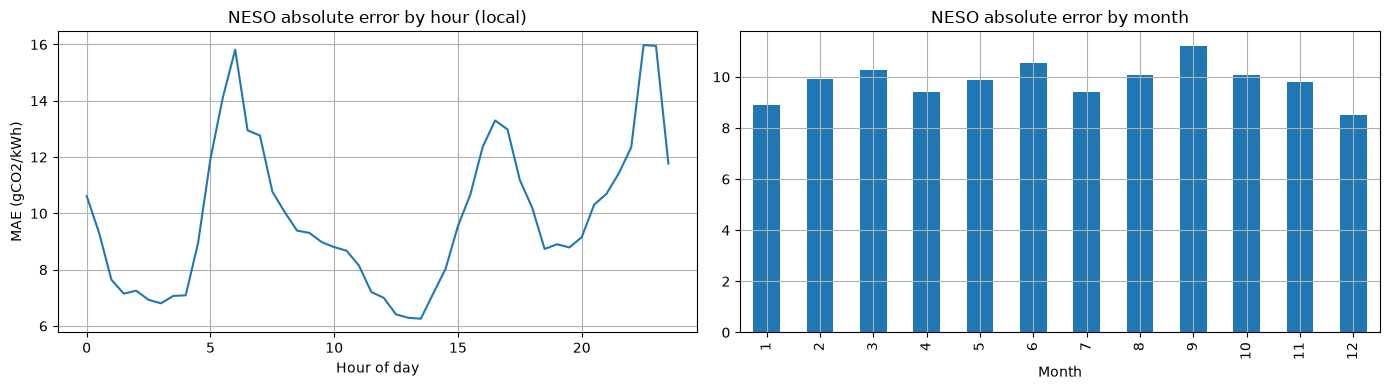

In [9]:
err = neso.dropna(subset=["actual", "forecast"]).copy()
err["error"] = err["forecast"] - err["actual"]
err["abs_error"] = err["error"].abs()

print(f"NESO MAE: {err['abs_error'].mean():.1f} gCO2/kWh | bias (forecast minus actual): {err['error'].mean():.1f}")
print(err.groupby(err["period_start"].dt.year)["abs_error"].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
err.groupby("hour_local")["abs_error"].mean().plot(ax=axes[0])
axes[0].set_title("NESO absolute error by hour (local)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MAE (gCO2/kWh)")

err.groupby("month")["abs_error"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("NESO absolute error by month")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()

## EDA summary

**Key patterns:**
- **Trend:** step down from 152 (2023) to ~125 (2024+), then a plateau. 2023 may be a different regime.
- **Daily profile:** winter double peak (07:00, 17:30); summer deep midday solar valley and later evening peak (19:30 local).
- **Time zone:** peak timing depends on sunset as well as demand; neither UTC nor local time alone aligns it.
- **Weekday vs weekend:** weekends 15 to 20% cleaner; the weekday morning peak nearly vanishes.
- **Seasonality:** month changes the daily shape; December is the cleanest month (Christmas demand drop).
- **Weather drivers:** wind dominates (North Sea Spearman -0.55); inland Scotland point is a weak proxy; temperature modest (-0.19); solar effect visible in daytime only; cloud cover negligible.
- **Autocorrelation:** ~0.6 at 24h, ~0.4 at 48h, fades after 3 days; no weekly peak.
- **NESO error:** historical MAE 9.9 with no bias, too accurate for a true day-ahead forecast. History likely stores near-real-time updates, so it is not a fair 24h benchmark.

**Features to build in Phase 2:**
- Calendar (UK local time): cyclical hour, day of week, cyclical day of year, UK bank holiday flag, Christmas period flag
- Solar elevation computed from timestamp (known in advance)
- Weather: combined wind index from offshore wind cluster points, capped wind proxy, London temperature, solar radiation; cloud cover low priority
- Lags relative to forecast origin: latest known value, t-24h, t-48h, plus a horizon feature

**Modelling and evaluation rules:**
- Time-based splits only; compare training on 2024+ vs all years
- Exclude outages, null `actual` and `actual` = 0 from training targets
- Benchmarks: naive (same time yesterday) now; NESO's day-ahead forecast via our own daily snapshots; report 9.9 only as a near-real-time ceiling

## Follow-up: offshore wind locations
Inland Scotland (Spearman -0.29) was replaced by offshore cluster points. Checking whether they carry more signal.

In [13]:
weather = load_folder("../data/raw/weather")
print("Locations:", sorted(weather["location"].unique()))
print(weather.groupby("location").size())

wind = weather.pivot_table(index="time", columns="location", values="wind_speed_100m")
wind.columns = [f"wind__{c}" for c in wind.columns]

merged_wind = neso.merge(wind, left_on="hour_key", right_index=True, how="inner")
corr_wind = merged_wind[wind.columns].corrwith(merged_wind["actual"], method="spearman").sort_values()
print("\nSpearman correlation with actual intensity:")
print(corr_wind.round(2))

# Combined wind index: average of the offshore points
offshore = ["wind__moray_firth", "wind__north_sea", "wind__east_anglia", "wind__irish_sea"]
merged_wind["wind_index"] = merged_wind[offshore].mean(axis=1)
print("\nWind index correlation:", round(merged_wind["wind_index"].corr(merged_wind["actual"], method="spearman"), 2))

Locations: ['east_anglia', 'irish_sea', 'london', 'moray_firth', 'north_sea', 'south_england_solar']
location
east_anglia            33096
irish_sea              33096
london                 33096
moray_firth            33096
north_sea              33096
south_england_solar    33096
dtype: int64

Spearman correlation with actual intensity:
wind__north_sea             -0.55
wind__irish_sea             -0.54
wind__east_anglia           -0.49
wind__london                -0.45
wind__south_england_solar   -0.43
wind__moray_firth           -0.32
dtype: float64

Wind index correlation: -0.6


In [14]:
wind.corr(method="spearman").round(2)

,wind__east_anglia,wind__irish_sea,wind__london,wind__moray_firth,wind__north_sea,wind__south_england_solar
wind__east_anglia,1.00,0.48,0.76,0.25,0.70,0.68
wind__irish_sea,0.48,1.00,0.50,0.44,0.61,0.49
wind__london,0.76,0.50,1.00,0.19,0.58,0.84
wind__moray_firth,0.25,0.44,0.19,1.00,0.41,0.18
wind__north_sea,0.70,0.61,0.58,0.41,1.00,0.52
wind__south_england_solar,0.68,0.49,0.84,0.18,0.52,1.00


In [15]:
for name, cols in {
    "all 4 offshore": ["wind__moray_firth", "wind__north_sea", "wind__east_anglia", "wind__irish_sea"],
    "without Moray": ["wind__north_sea", "wind__east_anglia", "wind__irish_sea"],
}.items():
    idx = merged_wind[cols].mean(axis=1)
    print(f"{name}: {idx.corr(merged_wind['actual'], method='spearman'):.3f}")

all 4 offshore: -0.605
without Moray: -0.613


**Takeaway:** Offshore points improve signal: Irish Sea (-0.54) and East Anglia (-0.49) are strong; Moray Firth (-0.32) barely beats inland Scotland (-0.29), so location was not the main issue (possible cause: Scottish wind matters less for national intensity, e.g. grid transfer limits; hypothesis only).A combined offshore wind index (-0.61 without Moray) beats every single location.. London and south England wind are redundant with East Anglia (0.68 to 0.84), so they are dropped as wind features (kept for temperature and solar). Irish Sea and Moray are the most independent points.
Wind features: offshore wind index, North Sea, Irish Sea, Moray Firth (separately).
Index composition: North Sea, East Anglia and Irish Sea (Spearman -0.613 vs -0.605 with Moray included). Moray is kept as a separate feature rather than in the index, to avoid double counting.